# Deep Learning Lab 08 — Complete Solution
**Student: Hajra Wajid** | **Roll number: 23-cp-60**

Transfer learning and data augmentation with PyTorch. All six tasks, plots, numerical observations, viva answers, and checkpoint export are included.


**Manual corrections:** digits 0–4 are **five**, not six classes. The source head is discarded even though the near target also has five classes. Section 7's ImageNet transform does not automatically convert every grayscale input to RGB; explicitly convert to RGB before using ImageNet transforms.


In [ ]:
import os, random, copy, json, math, time, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import MNIST, FashionMNIST
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode
from IPython.display import display, Markdown

SEED = 42
EPOCHS = 20
SOURCE_EPOCHS = 20
BATCH_SIZE = 64
LR = 1e-3
BUDGETS = [10, 25, 50, 100, 250, 500]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = Path('Lab08'); OUT.mkdir(exist_ok=True)
torch.set_num_threads(min(4, os.cpu_count() or 1))
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_all()
print('Device:', DEVICE, '| PyTorch:', torch.__version__)
print('Fixed target protocol: Adam, LR=', LR, ', epochs=', EPOCHS,
      ', batch=', BATCH_SIZE, ', seed=', SEED)


Device: cuda | PyTorch: 2.14.1+cu130
Fixed target protocol: Adam, LR= 0.001 , epochs= 20 , batch= 64 , seed= 42


## Fixed experimental protocol
Every target comparison uses Adam, cross-entropy, 20 epochs, batch size 64, LR 0.001 and seed 42. Images are scaled to [0,1], with no target-specific normalization. Training subsets are stratified, deterministic and nested: the first N examples of the same seeded per-class permutation. At a given N, strategies see exactly the same samples and minibatch order. Every strategy starts with the same randomly initialized head. Only the named experimental factor changes.

Task 6 intentionally varies backbone LR, warm-up, or unfrozen blocks. Task 5 intentionally varies augmentation. Source training is a separate task; its convergence is inspected from the loss curve. No early stopping or model choice uses the test set. Repeated test measurements are for the lab's requested descriptive comparisons, not an unbiased final deployment estimate. These are single-seed results, not statistical proof.


In [ ]:
mn_train = MNIST('data', train=True, download=True)
mn_test = MNIST('data', train=False, download=True)
fa_train = FashionMNIST('data', train=True, download=True)
fa_test = FashionMNIST('data', train=False, download=True)

def select(ds, classes):
    mask = torch.zeros_like(ds.targets, dtype=torch.bool)
    for c in classes: mask |= ds.targets == c
    x = ds.data[mask].unsqueeze(1).float() / 255.
    raw = ds.targets[mask]
    y = torch.empty_like(raw)
    for i, c in enumerate(classes): y[raw == c] = i
    return x, y

source_train = select(mn_train, range(5)); source_test = select(mn_test, range(5))
DATA = {'near': (select(mn_train, range(5,10)), select(mn_test, range(5,10))),
        'far': (select(fa_train, range(10)), select(fa_test, range(10)))}
CLASS_NAMES = {'near': [str(i) for i in range(5,10)], 'far': fa_train.classes}

def subset(domain, n):
    x,y = DATA[domain][0]
    g = torch.Generator().manual_seed(SEED)
    ids = []
    for c in range(len(CLASS_NAMES[domain])):
        pool = torch.where(y == c)[0]
        ids.append(pool[torch.randperm(len(pool), generator=g)[:n]])
    ids = torch.cat(ids)
    assert len(ids) == n * len(CLASS_NAMES[domain])
    return x[ids], y[ids]

class Net(nn.Module):
    def __init__(self, nclass, c1=16, c2=32, h=64):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Conv2d(1,c1,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(c1,c2,3,padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(c2*7*7,h),
                                  nn.ReLU(), nn.Linear(h,nclass))
    def forward(self,x): return self.head(self.backbone(x))

def count(model):
    return sum(p.numel() for p in model.parameters())

def loader(pair, shuffle=False, aug=None):
    class Images(Dataset):
        def __len__(self): return len(pair[1])
        def __getitem__(self,i):
            x = pair[0][i].clone()
            return (aug(x) if aug else x), pair[1][i]
    return DataLoader(Images(), batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(SEED), num_workers=0)

@torch.no_grad()
def accuracy(model, pair):
    model.eval(); right=0
    for x,y in loader(pair):
        pred = model(x.to(DEVICE)).argmax(1).cpu()
        right += (pred == y).sum().item()
    return 100 * right/len(pair[1])

def fit(model, train, test, epochs=EPOCHS, aug=None, ratio=1., warmup=0):
    model.to(DEVICE)
    # Include temporarily frozen parameters so warm-up unfreezing works.
    opt = torch.optim.Adam([
        {'params':list(model.backbone.parameters()), 'lr':LR*ratio},
        {'params':list(model.head.parameters()), 'lr':LR}])
    loss_fn=nn.CrossEntropyLoss(); hist=[]
    train_loader=loader(train, shuffle=True, aug=aug)
    for epoch in range(epochs):
        if warmup and epoch == warmup:
            for p in model.backbone.parameters(): p.requires_grad=True
        model.train(); total=0.; seen=0
        for x,y in train_loader:
            x,y=x.to(DEVICE),y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss=loss_fn(model(x),y); loss.backward(); opt.step()
            total += loss.item()*len(y); seen += len(y)
        hist.append({'epoch':epoch+1,'loss':total/seen,
                     'train':accuracy(model,train),'test':accuracy(model,test)})
    return pd.DataFrame(hist)

def filters(model, title, filename):
    w=model.backbone[0].weight.detach().cpu()[:,0]
    fig,axes=plt.subplots(2,8,figsize=(12,3))
    lim=w.abs().max().item()
    for i,ax in enumerate(axes.flat):
        ax.imshow(w[i],cmap='coolwarm',vmin=-lim,vmax=lim); ax.axis('off')
    fig.suptitle(title); fig.tight_layout(); fig.savefig(OUT/filename,dpi=150); plt.show()


100%|██████████| 9.91M/9.91M [00:00<00:00, 20.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 514kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.68MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.72MB/s]
100%|██████████| 26.4M/26.4M [00:01<00:00, 13.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.5MB/s]


## Task 1 — Source model (10 marks)
The source contains only digits 0–4, mapped to labels 0–4. We report the actual class counts rather than assuming exact balance. Convolutional edge and corner detectors can transfer to clothing; the digit-specific classification head is useless for garment labels and must be replaced.


,digit,training_count
0,0,5923
1,1,6742
2,2,5958
3,3,6131
4,4,5842


Source training size: 30596 Test size: 5139
Largest/smallest class ratio: 1.1540567874908447
Backbone: 4,800; head: 100,741; backbone share: 4.55%
Source test accuracy (full source training set, five classes): 99.88%


,epoch,loss,train,test
15,16,0.003889,99.993463,99.766492
16,17,0.000792,99.996732,99.824869
17,18,0.000166,100.000000,99.844328
18,19,0.000038,100.000000,99.883246
19,20,0.000021,100.000000,99.883246


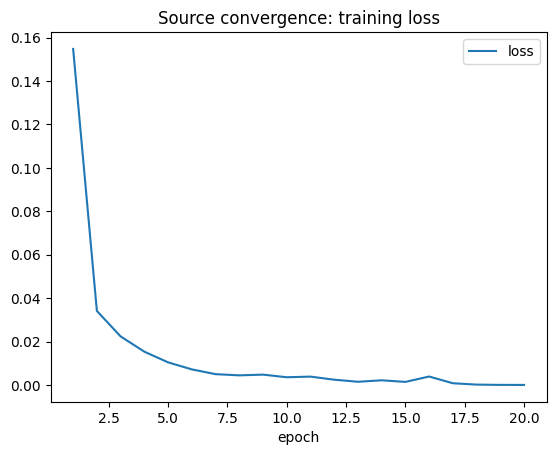

Loss five epochs from end: 0.00389; final: 0.00002. If loss is still falling substantially, increase SOURCE_EPOCHS and rerun ALL tasks.


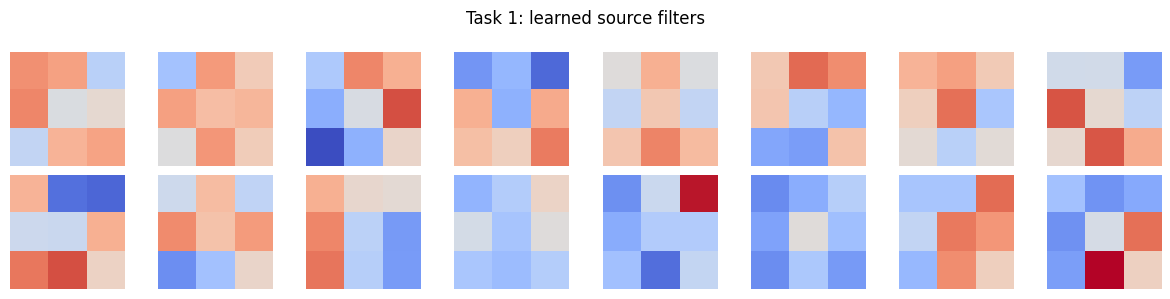

In [ ]:
counts = torch.bincount(source_train[1], minlength=5)
display(pd.DataFrame({'digit':range(5),'training_count':counts.numpy()}))
print('Source training size:', len(source_train[1]), 'Test size:',len(source_test[1]))
print('Largest/smallest class ratio:',float(counts.max()/counts.min()))
seed_all(); source=Net(5)
source_history=fit(source,source_train,source_test,epochs=SOURCE_EPOCHS)
source_backbone_state=copy.deepcopy({k:v.cpu() for k,v in source.backbone.state_dict().items()})
torch.save({'model_state_dict':{k:v.cpu() for k,v in source.state_dict().items()},
            'backbone_state_dict':source_backbone_state,'source_classes':list(range(5)),
            'seed':SEED,'epochs':SOURCE_EPOCHS,'learning_rate':LR}, OUT/'source_checkpoint.pt')
nb=count(source.backbone); nh=count(source.head)
print(f'Backbone: {nb:,}; head: {nh:,}; backbone share: {100*nb/(nb+nh):.2f}%')
print(f'Source test accuracy (full source training set, five classes): {accuracy(source,source_test):.2f}%')
display(source_history.tail())
source_history.plot(x='epoch',y='loss',title='Source convergence: training loss'); plt.show()
last=source_history.loss.iloc[-1]; previous=source_history.loss.iloc[-5]
print(f'Loss five epochs from end: {previous:.5f}; final: {last:.5f}. '
      'If loss is still falling substantially, increase SOURCE_EPOCHS and rerun ALL tasks.')
filters(source,'Task 1: learned source filters','task1_source_filters.png')


## Task 2 — Scratch, frozen and fine-tuned (15 marks)
A frozen backbone has `requires_grad=False`: no gradients accumulate on it and Adam cannot update it. Its parameters can safely be present in an optimizer because PyTorch skips parameters with no gradient; the manual's filtered-parameter optimizer is also valid. We verify freezing using both parameter counts and exact before/after weights. Accuracy curves include clean training accuracy and held-out test accuracy.


near N= 25 scratch  aug=none     ratio=1 warmup=0: train 97.60%, test 88.23%
near N= 25 frozen   aug=none     ratio=1 warmup=0: train 100.00%, test 94.61%
near N= 25 finetune aug=none     ratio=1 warmup=0: train 100.00%, test 94.28%


,domain,N,strategy,augmentation,backbone_lr_ratio,warmup_epochs,initial_trainable_parameters,train_accuracy,test_accuracy,gap
0,near,25,scratch,none,1.0,0,105541,97.6,88.232874,9.367126
1,near,25,frozen,none,1.0,0,100741,100.0,94.610163,5.389837
2,near,25,finetune,none,1.0,0,105541,100.0,94.281012,5.718988


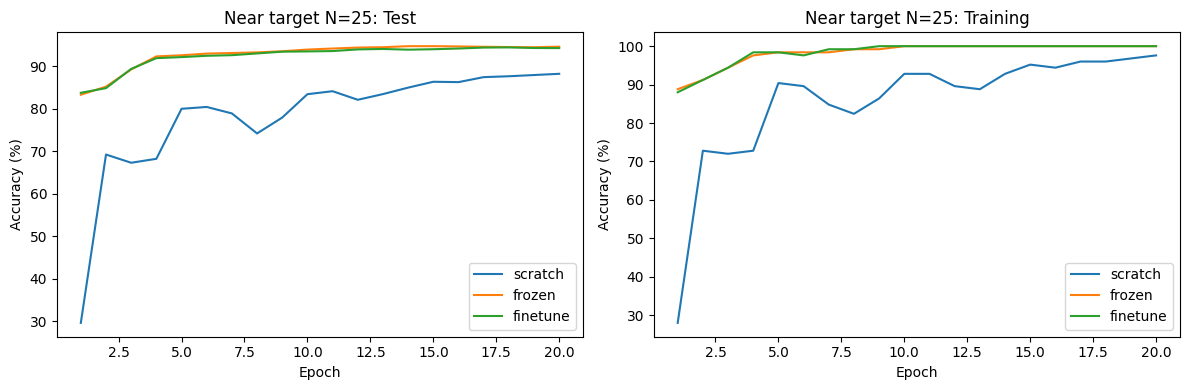

Choose frozen at N=25: highest observed test accuracy 94.61%.
Largest train-test gap: scratch, 9.37 percentage points. More trainable parameters increase capacity to memorize; optimization and initialization also matter.
scratch first epoch within 1 percentage point of its own final test accuracy: 17
frozen first epoch within 1 percentage point of its own final test accuracy: 10
finetune first epoch within 1 percentage point of its own final test accuracy: 9
Frozen features can converge quickly because only the head is learned; inspect measured epochs above.


In [ ]:
def make(domain, mode, warmup=0):
    seed_all(); m=Net(len(CLASS_NAMES[domain]))
    if mode != 'scratch': m.backbone.load_state_dict(source_backbone_state)
    if mode == 'frozen' or warmup:
        for p in m.backbone.parameters(): p.requires_grad=False
    if mode == 'partial':
        for p in m.backbone[0].parameters(): p.requires_grad=False
    return m

RESULTS={}; HISTORIES={}; STATES={}
def run(domain,n,mode,aug_name='none',ratio=1.,warmup=0):
    key=(domain,n,mode,aug_name,ratio,warmup)
    if key in RESULTS: return RESULTS[key]
    m=make(domain,mode,warmup)
    trainable=sum(p.numel() for p in m.parameters() if p.requires_grad)
    initial=copy.deepcopy(m.backbone.state_dict())
    seed_all()
    h=fit(m,subset(domain,n),DATA[domain][1],
          aug=AUGS.get(aug_name),ratio=ratio,warmup=warmup)
    if mode=='frozen':
        assert all(torch.equal(initial[k].cpu(),v.cpu()) for k,v in m.backbone.state_dict().items())
    row={'domain':domain,'N':n,'strategy':mode,'augmentation':aug_name,
         'backbone_lr_ratio':ratio,'warmup_epochs':warmup,
         'initial_trainable_parameters':trainable,
         'train_accuracy':float(h.train.iloc[-1]),'test_accuracy':float(h.test.iloc[-1])}
    row['gap']=row['train_accuracy']-row['test_accuracy']
    RESULTS[key]=row; HISTORIES[key]=h
    STATES[key]={k:v.detach().cpu().clone() for k,v in m.backbone.state_dict().items()}
    print(f'{domain:4s} N={n:3d} {mode:8s} aug={aug_name:8s} ratio={ratio:g} warmup={warmup}: '
          f'train {row["train_accuracy"]:.2f}%, test {row["test_accuracy"]:.2f}%')
    pd.DataFrame(RESULTS.values()).to_csv(OUT/'all_results.csv',index=False)
    return row
AUGS={'none':None}
MODES=['scratch','frozen','finetune']
t2=pd.DataFrame([run('near',25,s) for s in MODES]); display(t2)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for mode in MODES:
    h=HISTORIES[('near',25,mode,'none',1.,0)]
    axes[0].plot(h.epoch,h.test,label=mode); axes[1].plot(h.epoch,h.train,label=mode)
for ax,label in zip(axes,['Test','Training']):
    ax.set(xlabel='Epoch',ylabel='Accuracy (%)',title=f'Near target N=25: {label}'); ax.legend()
fig.tight_layout(); fig.savefig(OUT/'task2_curves.png',dpi=150); plt.show()
w=t2.loc[t2.test_accuracy.idxmax()]; over=t2.loc[t2.gap.idxmax()]
print(f'Choose {w.strategy} at N=25: highest observed test accuracy {w.test_accuracy:.2f}%.')
print(f'Largest train-test gap: {over.strategy}, {over.gap:.2f} percentage points. '
      'More trainable parameters increase capacity to memorize; optimization and initialization also matter.')
for mode in MODES:
    h=HISTORIES[('near',25,mode,'none',1.,0)]
    e=h.loc[h.test >= h.test.iloc[-1]-1,'epoch'].iloc[0]
    print(mode, 'first epoch within 1 percentage point of its own final test accuracy:',e)
print('Frozen features can converge quickly because only the head is learned; inspect measured epochs above.')


## Task 3 — Data-budget sweep (25 marks)
All accuracies use the full near-target test set. Transfer advantage means **max(frozen, fine-tuned) − scratch**, in percentage points. We do not force the expected ordering: it is valid for transfer to hurt or for no crossover to occur.


near N= 10 scratch  aug=none     ratio=1 warmup=0: train 92.00%, test 76.01%
near N= 10 frozen   aug=none     ratio=1 warmup=0: train 100.00%, test 88.77%
near N= 10 finetune aug=none     ratio=1 warmup=0: train 100.00%, test 87.74%
near N= 50 scratch  aug=none     ratio=1 warmup=0: train 98.40%, test 90.72%
near N= 50 frozen   aug=none     ratio=1 warmup=0: train 100.00%, test 95.52%
near N= 50 finetune aug=none     ratio=1 warmup=0: train 100.00%, test 95.04%
near N=100 scratch  aug=none     ratio=1 warmup=0: train 97.60%, test 92.72%
near N=100 frozen   aug=none     ratio=1 warmup=0: train 100.00%, test 97.10%
near N=100 finetune aug=none     ratio=1 warmup=0: train 100.00%, test 96.56%
near N=250 scratch  aug=none     ratio=1 warmup=0: train 99.76%, test 96.17%
near N=250 frozen   aug=none     ratio=1 warmup=0: train 100.00%, test 98.33%
near N=250 finetune aug=none     ratio=1 warmup=0: train 100.00%, test 98.09%
near N=500 scratch  aug=none     ratio=1 warmup=0: train 99.84%, tes

strategy,finetune,frozen,scratch
N,,,
10,87.739148,88.767743,76.013166
25,94.281012,94.610163,88.232874
50,95.042172,95.515326,90.722074
100,96.564493,97.099362,92.717548
250,98.086813,98.333676,96.173627
500,98.539395,98.601111,97.983954


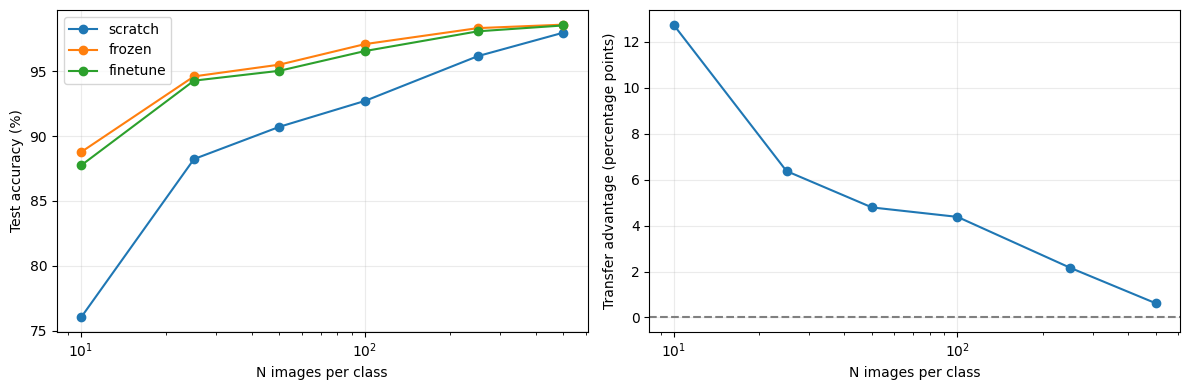

Advantage: N=10: 12.75 pp; N=500: 0.62 pp
Largest/smallest-budget signed advantage ratio: 0.048. A sign change means reversal, not a meaningful multiplicative saving.
Advantage shrank by a factor of 20.667 (below 1 means it grew).
Observed frozen-to-finetune crossover budgets: none within range
Fine-tuning adapts more parameters and may benefit from more data; freezing limits variance. If fine-tuning wins throughout, no small-budget freezing regime was observed; if freezing wins throughout, extra adaptation was not beneficial in this range.
Estimated scratch N=165.2 to match frozen N=25; scratch/frozen data ratio=6.61x.
At the smallest measured budget, use frozen based on this run.
At the largest measured budget, use frozen; no freezing-to-fine-tuning threshold was established.


In [ ]:
def sweep(domain):
    return pd.DataFrame([run(domain,n,s) for n in BUDGETS for s in MODES])
def wide(frame):
    return frame.pivot(index='N',columns='strategy',values='test_accuracy').sort_index()
def advantage(w): return w[['frozen','finetune']].max(axis=1)-w['scratch']
near=sweep('near'); nw=wide(near); na=advantage(nw)
display(nw)
fig,ax=plt.subplots(1,2,figsize=(12,4))
for mode in MODES: ax[0].plot(nw.index,nw[mode],marker='o',label=mode)
ax[1].plot(na.index,na,marker='o'); ax[1].axhline(0,color='gray',ls='--')
for a in ax: a.set_xscale('log'); a.set_xlabel('N images per class'); a.grid(alpha=.25)
ax[0].set_ylabel('Test accuracy (%)'); ax[0].legend()
ax[1].set_ylabel('Transfer advantage (percentage points)')
fig.tight_layout(); fig.savefig(OUT/'task3_sweep.png',dpi=150); plt.show()
print(f'Advantage: N=10: {na.loc[10]:.2f} pp; N=500: {na.loc[500]:.2f} pp')
if abs(na.loc[10])>1e-9:
    print(f'Largest/smallest-budget signed advantage ratio: {na.loc[500]/na.loc[10]:.3f}. '
          'A sign change means reversal, not a meaningful multiplicative saving.')
else: print('Change factor undefined because the initial advantage is zero.')
if na.loc[10]>0 and na.loc[500]>0:
    print(f'Advantage shrank by a factor of {na.loc[10]/na.loc[500]:.3f} (below 1 means it grew).')
diff=nw.finetune-nw.frozen
cross=[BUDGETS[i] for i in range(1,len(BUDGETS)) if diff.iloc[i]>0 and diff.iloc[i-1]<=0]
print('Observed frozen-to-finetune crossover budgets:', cross or 'none within range')
print('Fine-tuning adapts more parameters and may benefit from more data; freezing limits variance. '
      'If fine-tuning wins throughout, no small-budget freezing regime was observed; '
      'if freezing wins throughout, extra adaptation was not beneficial in this range.')
target=nw.loc[25,'frozen']; xs=nw.index.to_numpy(); ys=nw.scratch.to_numpy()
match=None
if ys[0]>=target:
    print('Scratch already matches the frozen N=25 result at N=10; required N is at most 10.')
    print('Data-saving ratio is at most 10/25 = 0.40; no demonstrated saving for freezing.')
else:
    for i in range(1,len(xs)):
        if ys[i]>=target and ys[i-1]<target:
            # Interpolate on the logarithmic horizontal scale used in the figure.
            f=(target-ys[i-1])/(ys[i]-ys[i-1])
            match=float(np.exp(np.log(xs[i-1])+f*(np.log(xs[i])-np.log(xs[i-1])))); break
    if match is None:
        print('Scratch does not match frozen N=25 within N<=500; required data >500, ratio >20x.')
    else: print(f'Estimated scratch N={match:.1f} to match frozen N=25; scratch/frozen data ratio={match/25:.2f}x.')
best=nw.idxmax(axis=1)
if cross:
    x=cross[0]
    print(f'With fewer than {x} images per class, consider frozen features if the measured lower-budget results support them.')
    print(f'At or above {x}, consider fine-tuning; confirm against scratch at the available budget.')
else:
    print(f'At the smallest measured budget, use {best.iloc[0]} based on this run.')
    print(f'At the largest measured budget, use {best.iloc[-1]}; no freezing-to-fine-tuning threshold was established.')


## Task 4 — Domain gap (15 marks)
Fashion-MNIST has 10 classes (chance 10%); the near task has 5 classes (chance 20%). Absolute accuracy is therefore not a controlled domain-only comparison: class count and task difficulty also differ. The manual's transfer-advantage comparison helps, but does not isolate domain distance causally.

Frozen digit filters reuse local edges, corners and simple contours that clothing also contains. Fine-tuning can adapt later features to clothing textures and shapes, whereas freezing cannot. In a medical application, transfer from natural-image object recognition to raw ECG waveforms may fail because the modality and useful patterns differ; use a suitable 1-D architecture with ECG pretraining, self-supervised learning, or supervised training on adequate in-domain data.


far  N= 10 scratch  aug=none     ratio=1 warmup=0: train 74.00%, test 64.80%
far  N= 10 frozen   aug=none     ratio=1 warmup=0: train 96.00%, test 73.18%
far  N= 10 finetune aug=none     ratio=1 warmup=0: train 99.00%, test 74.20%
far  N= 25 scratch  aug=none     ratio=1 warmup=0: train 84.00%, test 73.07%
far  N= 25 frozen   aug=none     ratio=1 warmup=0: train 96.80%, test 78.71%
far  N= 25 finetune aug=none     ratio=1 warmup=0: train 99.60%, test 77.89%
far  N= 50 scratch  aug=none     ratio=1 warmup=0: train 84.20%, test 77.71%
far  N= 50 frozen   aug=none     ratio=1 warmup=0: train 97.80%, test 80.82%
far  N= 50 finetune aug=none     ratio=1 warmup=0: train 98.60%, test 81.48%
far  N=100 scratch  aug=none     ratio=1 warmup=0: train 85.80%, test 79.64%
far  N=100 frozen   aug=none     ratio=1 warmup=0: train 96.30%, test 83.17%
far  N=100 finetune aug=none     ratio=1 warmup=0: train 97.60%, test 83.07%
far  N=250 scratch  aug=none     ratio=1 warmup=0: train 87.72%, test 84.34%

strategy,finetune,frozen,scratch
N,,,
10,74.20,73.18,64.80
25,77.89,78.71,73.07
50,81.48,80.82,77.71
100,83.07,83.17,79.64
250,85.53,85.35,84.34
500,86.74,86.03,86.31


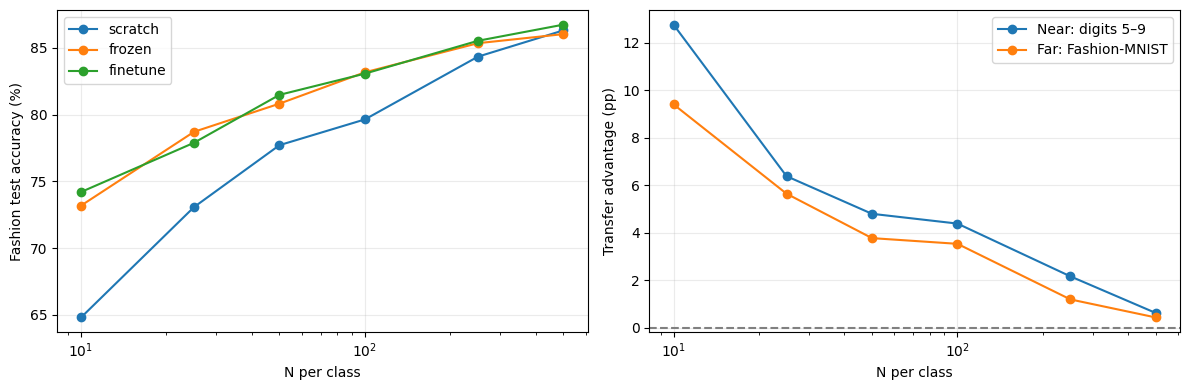

,near_advantage_pp,far_advantage_pp,near_minus_far_pp
N,,,
10,12.754577,9.40,3.354577
25,6.377289,5.64,0.737289
50,4.793252,3.77,1.023252
100,4.381814,3.53,0.851814
250,2.160049,1.19,0.970049
500,0.617157,0.43,0.187157


Mean near-minus-far advantage: 1.19 pp; positive means near is larger.
Far-target fine-tune minus frozen (pp):


,difference
N,
10,1.02
25,-0.82
50,0.66
100,-0.10
250,0.18
500,0.71


Interpret the measured signs: a larger domain gap often favors adaptation, but this is an empirical result, not a guarantee.


In [ ]:
far=sweep('far'); fw=wide(far); fa=advantage(fw); display(fw)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for mode in MODES: axes[0].plot(fw.index,fw[mode],marker='o',label=mode)
axes[0].set_ylabel('Fashion test accuracy (%)'); axes[0].legend()
axes[1].plot(na.index,na,marker='o',label='Near: digits 5–9')
axes[1].plot(fa.index,fa,marker='o',label='Far: Fashion-MNIST')
axes[1].axhline(0,color='gray',ls='--'); axes[1].set_ylabel('Transfer advantage (pp)'); axes[1].legend()
for ax in axes: ax.set_xscale('log'); ax.set_xlabel('N per class'); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(OUT/'task4_domain_gap.png',dpi=150); plt.show()
display(pd.DataFrame({'near_advantage_pp':na,'far_advantage_pp':fa,'near_minus_far_pp':na-fa}))
print(f'Mean near-minus-far advantage: {(na-fa).mean():.2f} pp; positive means near is larger.')
print('Far-target fine-tune minus frozen (pp):'); display((fw.finetune-fw.frozen).rename('difference'))
print('Interpret the measured signs: a larger domain gap often favors adaptation, but this is an empirical result, not a guarantee.')


## Task 5 — Data augmentation (20 marks)
The four transforms below are implemented explicitly. Shift uses zero-filled slicing (no wrap), flip reverses the width, rotation uses a sampled angle and torchvision's geometric resampling, and erasing blanks a small rectangle. Each sample gets fresh random transforms whenever it is loaded for training. Test images and the clean training evaluation set are never augmented.

The label-preserving near-target combination is shift + small rotation + erasing. Horizontal flip is studied separately because it can invalidate digit labels. A garment's category usually survives mirroring, while digit orientation and handedness can define the label. This is the **label-preserving invariance principle**. For medical imaging, indiscriminate left-right flips would be invalid when predicting anatomical laterality, such as left versus right lung disease.


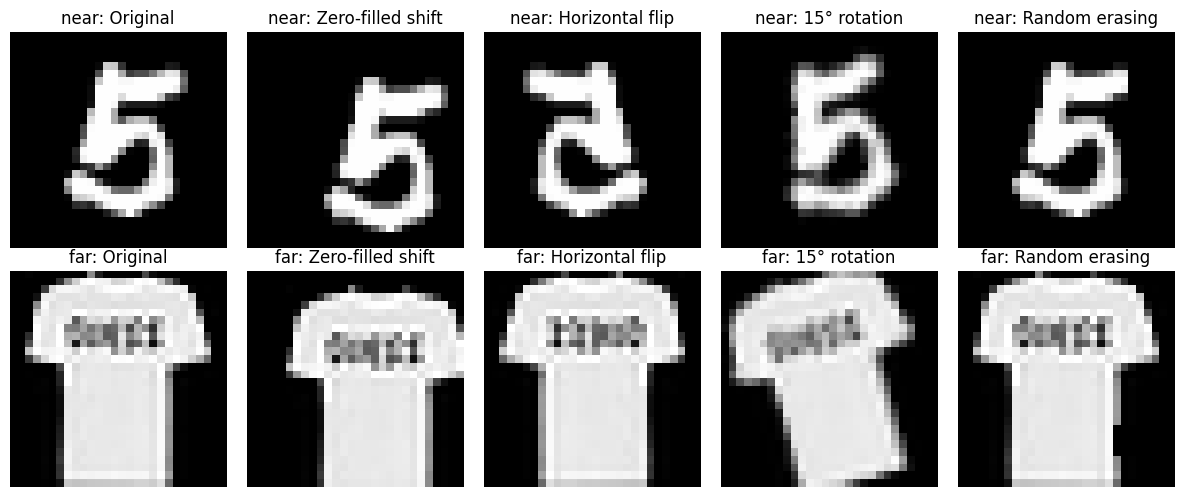

near N= 25 scratch  aug=combined ratio=1 warmup=0: train 86.40%, test 80.99%
near N= 25 finetune aug=combined ratio=1 warmup=0: train 100.00%, test 94.75%
near N=100 scratch  aug=combined ratio=1 warmup=0: train 93.00%, test 92.29%
near N=100 finetune aug=combined ratio=1 warmup=0: train 99.20%, test 97.45%


,N,strategy,without,with,gain_pp
0,25,scratch,88.232874,80.991566,-7.241308
1,25,finetune,94.281012,94.754166,0.473154
2,100,scratch,92.717548,92.285538,-0.432010
3,100,finetune,96.564493,97.449085,0.884592


N=25: scratch=88.23, augmentation=80.99, transfer=94.28, combined=94.75%; interaction=7.71 pp.
Both together outperform either individually; gains need not be exactly additive.
Exact additivity corresponds to interaction=0; single-seed differences may be noise.
N=100: scratch=92.72, augmentation=92.29, transfer=96.56, combined=97.45%; interaction=1.32 pp.
Both together outperform either individually; gains need not be exactly additive.
Exact additivity corresponds to interaction=0; single-seed differences may be noise.
near N= 25 scratch  aug=flip     ratio=1 warmup=0: train 88.00%, test 82.60%
near N=100 scratch  aug=flip     ratio=1 warmup=0: train 94.20%, test 90.76%
far  N= 25 scratch  aug=flip     ratio=1 warmup=0: train 78.00%, test 70.81%
far  N=100 scratch  aug=flip     ratio=1 warmup=0: train 84.00%, test 78.37%


,domain,N,strategy,baseline,flip,flip_gain_pp
0,near,25,scratch,88.232874,82.596174,-5.63670
1,near,100,scratch,92.717548,90.763217,-1.95433
2,far,25,scratch,73.070000,70.810000,-2.26000
3,far,100,scratch,79.640000,78.370000,-1.27000


near N= 25 scratch  aug=shift    ratio=1 warmup=0: train 88.00%, test 83.19%
near N= 25 scratch  aug=rotation ratio=1 warmup=0: train 97.60%, test 89.08%
near N= 25 scratch  aug=erasing  ratio=1 warmup=0: train 97.60%, test 88.27%
near N=100 scratch  aug=shift    ratio=1 warmup=0: train 95.00%, test 94.08%
near N=100 scratch  aug=rotation ratio=1 warmup=0: train 97.80%, test 93.99%
near N=100 scratch  aug=erasing  ratio=1 warmup=0: train 97.40%, test 92.74%


,N,strategy,augmentation,test_accuracy,gain_pp
0,25,scratch,shift,83.192759,-5.040115
1,25,scratch,rotation,89.076322,0.843448
2,25,scratch,erasing,88.274018,0.041144
3,25,scratch,flip,82.596174,-5.636700
4,100,scratch,shift,94.075293,1.357745
5,100,scratch,rotation,93.993006,1.275458
6,100,scratch,erasing,92.738120,0.020572
7,100,scratch,flip,90.763217,-1.954330


N=25: best single augmentation=rotation, gain=0.84 pp; small-angle orientation tolerance.
N=100: best single augmentation=shift, gain=1.36 pp; translation invariance.


In [ ]:
def shift(x, dx=None, dy=None):
    if dx is None: dx=int(torch.randint(-3,4,()).item())
    if dy is None: dy=int(torch.randint(-3,4,()).item())
    out=torch.zeros_like(x); h,w=x.shape[-2:]
    out[:,max(0,dy):min(h,h+dy),max(0,dx):min(w,w+dx)] =         x[:,max(0,-dy):min(h,h-dy),max(0,-dx):min(w,w-dx)]
    return out

def flip(x, force=False):
    return torch.flip(x,[-1]) if force or torch.rand(()).item()<.5 else x

def rotate(x, angle=None):
    if angle is None: angle=float(torch.empty(()).uniform_(-15,15))
    return TF.rotate(x,angle,interpolation=InterpolationMode.BILINEAR,fill=0)

def erase(x, force=False):
    out=x.clone()
    if force or torch.rand(()).item()<.5:
        h=int(torch.randint(3,8,()).item()); w=int(torch.randint(3,8,()).item())
        y=int(torch.randint(0,29-h,()).item()); z=int(torch.randint(0,29-w,()).item())
        out[:,y:y+h,z:z+w]=0
    return out

def combined(x): return erase(rotate(shift(x)))
AUGS.update({'shift':shift,'flip':flip,'rotation':rotate,'erasing':erase,'combined':combined})
seed_all()
fig,axes=plt.subplots(2,5,figsize=(12,5))
for row,domain in enumerate(['near','far']):
    x=subset(domain,25)[0][0]
    views=[x,shift(x,3,2),flip(x,True),rotate(x,15),erase(x,True)]
    for ax,v,title in zip(axes[row],views,['Original','Zero-filled shift','Horizontal flip','15° rotation','Random erasing']):
        ax.imshow(v[0],cmap='gray',vmin=0,vmax=1); ax.set_title(domain+': '+title); ax.axis('off')
fig.tight_layout(); fig.savefig(OUT/'task5_augmentation_examples.png',dpi=150); plt.show()
# Check that shifting never wraps content from the opposite border.
z=torch.zeros(1,28,28); z[0,0,0]=1
assert shift(z,-1,0).sum()==0

combo_rows=[]
for n in [25,100]:
    for mode in ['scratch','finetune']:
        base=run('near',n,mode)
        aug=run('near',n,mode,'combined')
        combo_rows.append({'N':n,'strategy':mode,'without':base['test_accuracy'],
                           'with':aug['test_accuracy'],'gain_pp':aug['test_accuracy']-base['test_accuracy']})
display(pd.DataFrame(combo_rows))
for n in [25,100]:
    b=run('near',n,'scratch')['test_accuracy']
    a=run('near',n,'scratch','combined')['test_accuracy']
    t=run('near',n,'finetune')['test_accuracy']
    both=run('near',n,'finetune','combined')['test_accuracy']
    interaction=both-t-a+b
    print(f'N={n}: scratch={b:.2f}, augmentation={a:.2f}, transfer={t:.2f}, '
          f'combined={both:.2f}%; interaction={interaction:.2f} pp.')
    if both < max(a,t): print('Combination is worse than the best individual method in this run.')
    elif both > max(a,t): print('Both together outperform either individually; gains need not be exactly additive.')
    else: print('Combination matches the best method; no extra benefit measured.')
    print('Exact additivity corresponds to interaction=0; single-seed differences may be noise.')

flip_rows=[]
for domain in ['near','far']:
    for n in [25,100]:
        b=run(domain,n,'scratch'); f=run(domain,n,'scratch','flip')
        flip_rows.append({'domain':domain,'N':n,'strategy':'scratch',
                          'baseline':b['test_accuracy'],'flip':f['test_accuracy'],
                          'flip_gain_pp':f['test_accuracy']-b['test_accuracy']})
display(pd.DataFrame(flip_rows))
# Single-transform ablation, including the intentionally questionable flip.
singles=[]
for n in [25,100]:
    baseline=run('near',n,'scratch')['test_accuracy']
    for aug in ['shift','rotation','erasing','flip']:
        r=run('near',n,'scratch',aug)
        singles.append({'N':n,'strategy':'scratch','augmentation':aug,
                        'test_accuracy':r['test_accuracy'],'gain_pp':r['test_accuracy']-baseline})
single_df=pd.DataFrame(singles); display(single_df)
meaning={'shift':'translation invariance','rotation':'small-angle orientation tolerance',
         'erasing':'robustness to local occlusion','flip':'mirror invariance (not reliably valid for digits)'}
for n,g in single_df.groupby('N'):
    w=g.loc[g.gain_pp.idxmax()]
    print(f'N={n}: best single augmentation={w.augmentation}, gain={w.gain_pp:.2f} pp; {meaning[w.augmentation]}.')
    if w.gain_pp<=0: print('No single augmentation improved on baseline in this run.')


## Task 6 — Fine-tuning mechanics (15 marks)
Use the near target with N=100. The head LR remains 0.001; the backbone uses 1, 0.1 or 0.01 times that value. Warm-up freezes the backbone for exactly the first five epochs and then unfreezes it for the remaining 15, preserving the same total budget. Partial unfreezing adapts only convolutional block 2 and the head.

A random head can send large, initially unhelpful gradients into a pretrained backbone. Large backbone steps may erase useful source representations (catastrophic forgetting). Smaller backbone LR and head warm-up can reduce this risk. Target accuracy alone does **not** prove catastrophic forgetting; proving source-task forgetting requires evaluating the retained source head on the source task, so our conclusions here concern the observed target performance and filter drift.


near N=100 finetune aug=none     ratio=0.1 warmup=0: train 100.00%, test 96.93%
near N=100 finetune aug=none     ratio=0.01 warmup=0: train 100.00%, test 97.14%


,domain,N,strategy,augmentation,backbone_lr_ratio,warmup_epochs,initial_trainable_parameters,train_accuracy,test_accuracy,gap
0,near,100,finetune,none,1.00,0,105541,100.0,96.564493,3.435507
1,near,100,finetune,none,0.10,0,105541,100.0,96.934787,3.065213
2,near,100,finetune,none,0.01,0,105541,100.0,97.140506,2.859494


Best observed backbone/head LR ratio: 0.01; test=97.14%.
near N=100 partial  aug=none     ratio=1 warmup=0: train 100.00%, test 96.59%
near N=100 finetune aug=none     ratio=1 warmup=5: train 100.00%, test 96.65%


,domain,N,strategy,augmentation,backbone_lr_ratio,warmup_epochs,initial_trainable_parameters,train_accuracy,test_accuracy,gap
0,near,100,frozen,none,1.0,0,100741,100.0,97.099362,2.900638
1,near,100,partial,none,1.0,0,105381,100.0,96.585065,3.414935
2,near,100,finetune,none,1.0,0,105541,100.0,96.564493,3.435507
3,near,100,finetune,none,1.0,5,100741,100.0,96.646780,3.353220


Warm-up minus immediate unfreezing: 0.08 pp (20 total epochs each).
Best observed adaptation configuration: frozen warm-up= 0
If partial matches full, adapting block 2 may suffice; if full wins clearly, block 1 adaptation also helps. Compare with frozen to judge the value of adaptation overall.


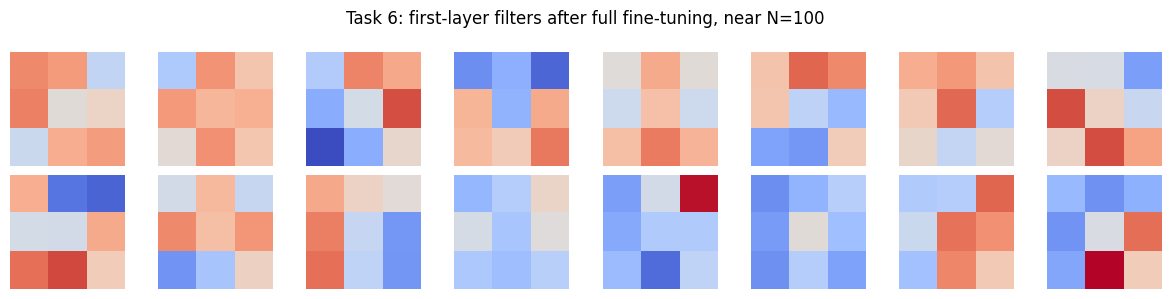

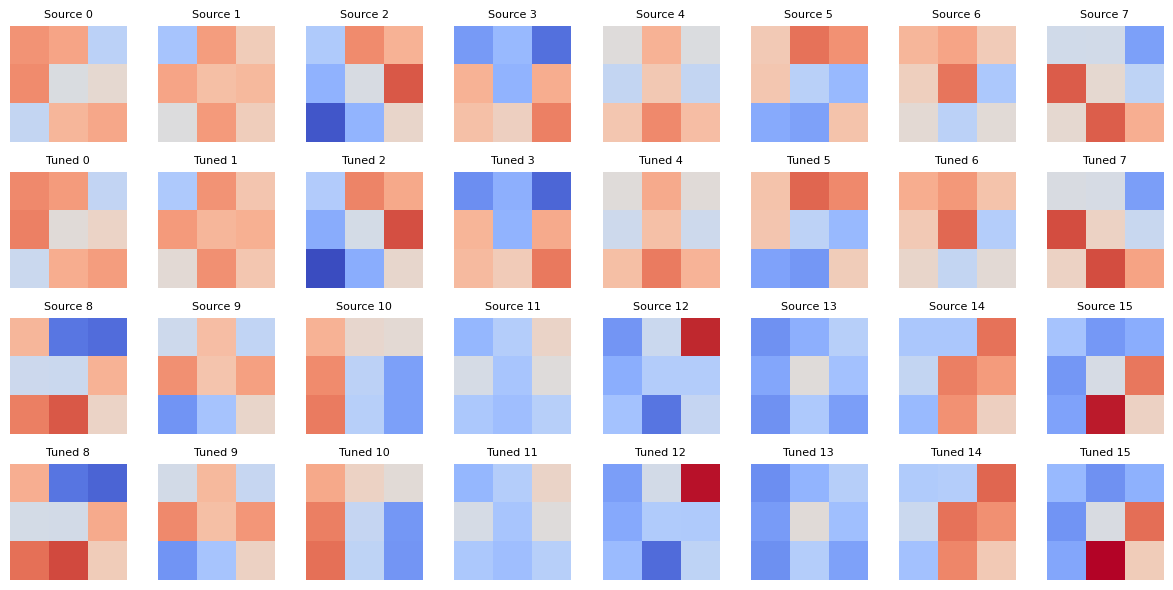

,N,strategy,block,mean_absolute_change,relative_L2_change
0,100,frozen,conv1,0.000000,0.000000
1,100,frozen,conv2,0.000000,0.000000
2,100,partial,conv1,0.000000,0.000000
3,100,partial,conv2,0.019543,0.172126
4,100,finetune,conv1,0.027985,0.099237
5,100,finetune,conv2,0.017968,0.158661


Frozen drift should be zero in both blocks; partial drift should be zero in block 1. Use relative L2 change to compare differently scaled layers. Drift shows adaptation, but performance comparisons determine whether that adaptation was useful.


In [ ]:
lr_rows=[run('near',100,'finetune',ratio=r) for r in [1.,.1,.01]]
lr_df=pd.DataFrame(lr_rows); display(lr_df)
w=lr_df.loc[lr_df.test_accuracy.idxmax()]
print(f'Best observed backbone/head LR ratio: {w.backbone_lr_ratio:g}; test={w.test_accuracy:.2f}%.')
# Schedule and freezing comparisons hold the standard ratio at 1.
mechanics=pd.DataFrame([run('near',100,'frozen'),run('near',100,'partial'),
                       run('near',100,'finetune'),run('near',100,'finetune',warmup=5)])
display(mechanics)
base=run('near',100,'finetune')['test_accuracy']
warm=run('near',100,'finetune',warmup=5)['test_accuracy']
print(f'Warm-up minus immediate unfreezing: {warm-base:.2f} pp (20 total epochs each).')
best_row=mechanics.loc[mechanics.test_accuracy.idxmax()]
print('Best observed adaptation configuration:',best_row.strategy,'warm-up=',best_row.warmup_epochs)
print('If partial matches full, adapting block 2 may suffice; if full wins clearly, block 1 adaptation also helps. '
      'Compare with frozen to judge the value of adaptation overall.')

m=make('near','finetune')
state=STATES[('near',100,'finetune','none',1.,0)]; m.backbone.load_state_dict(state)
filters(m,'Task 6: first-layer filters after full fine-tuning, near N=100','task6_finetuned_filters.png')
# Paired plots use the SAME color range for a meaningful visual comparison.
a=source_backbone_state['0.weight'][:,0]; b=state['0.weight'][:,0]
fig,axes=plt.subplots(4,8,figsize=(12,6)); lim=max(a.abs().max(),b.abs().max()).item()
for i in range(16):
    for row,wgt,label in [(2*(i//8),a,'Source'),(2*(i//8)+1,b,'Tuned')]:
        ax=axes[row,i%8]; ax.imshow(wgt[i],cmap='coolwarm',vmin=-lim,vmax=lim)
        ax.set_title(f'{label} {i}',fontsize=8); ax.axis('off')
fig.tight_layout(); fig.savefig(OUT/'task6_paired_filters.png',dpi=150); plt.show()
drift=[]
for mode in ['frozen','partial','finetune']:
    state=STATES[('near',100,mode,'none',1.,0)]
    for key,block in [('0.weight','conv1'),('3.weight','conv2')]:
        old=source_backbone_state[key]; new=state[key]
        mad=(new-old).abs().mean().item()
        relative=(new-old).norm().item()/max(old.norm().item(),1e-12)
        drift.append({'N':100,'strategy':mode,'block':block,'mean_absolute_change':mad,
                      'relative_L2_change':relative})
display(pd.DataFrame(drift))
print('Frozen drift should be zero in both blocks; partial drift should be zero in block 1. '
      'Use relative L2 change to compare differently scaled layers. Drift shows adaptation, '
      'but performance comparisons determine whether that adaptation was useful.')


## Viva answers (all 12)
1. Transfer the backbone and replace the head. The old outputs represent different labels even when the class counts match.
2. Set `requires_grad=False`; count trainable parameters and confirm frozen weights stay exactly unchanged.
3. The Task 2 printed winner and table give the measured answer at 25 images per class. Explain it using usable source features and trainable capacity.
4. Read Task 3's N=500 advantage: positive means transfer improved measured test accuracy, negative means scratch won. Weigh any gain against source-pretraining cost.
5. Freezing can reduce variance with scarce labels; fine-tuning's flexibility also allows overfitting. This is a tendency, not a guaranteed ordering.
6. Edges, corners, contours and other local visual primitives can be shared across domains.
7. Catastrophic forgetting is loss of previously learned capabilities during new training. Use smaller backbone learning rates and a head warm-up; preserving source behavior can also require rehearsal or explicit regularization.
8. Clothing category typically survives mirroring; digit identity may not. An augmentation should preserve the target label.
9. Use the N=25 and N=50 results to choose a strategy around 40 labels per class, then validate on held-out training-domain data. Avoid claiming an unmeasured threshold as certain.
10. See Task 5's four-way comparisons and interaction term: the answer depends on the observed gains; augmentation and transfer address different sources of prior information.
11. Frozen features are constant, so compute them once and train the head on cached tensors. This reduces repeated convolution work. Fresh stochastic augmentation would require new features, so caching one fixed view changes that training experiment.
12. Task 6 reports mean absolute and relative L2 changes for both convolutional layers. Compare relative drift with adaptation accuracy; larger drift alone does not establish usefulness.

## Submission
The manual asks for a notebook with outputs and a source checkpoint in `DeepLearningLab_<YourRollNo>/Lab08`. After running all cells, choose **File → Save a copy in Drive**, then **File → Download → Download .ipynb** to preserve outputs. Rename using your roll number. The ZIP below contains the source checkpoint, tables and figures; add your executed notebook to the same Lab08 folder before pushing your repository. No repository is modified automatically.


In [ ]:
results=pd.DataFrame(RESULTS.values())
results.to_csv(OUT/'all_results.csv',index=False)
source_history.to_csv(OUT/'source_training_history.csv',index=False)
pd.DataFrame(drift).to_csv(OUT/'filter_drift.csv',index=False)
for i,(key,h) in enumerate(HISTORIES.items()):
    h.to_csv(OUT/f'history_{i:03d}.csv',index=False)
manifest={f'history_{i:03d}.csv':list(key) for i,key in enumerate(HISTORIES)}
(OUT/'history_manifest.json').write_text(json.dumps(manifest,indent=2))
protocol={'seed':SEED,'epochs':EPOCHS,'source_epochs':SOURCE_EPOCHS,
          'batch_size':BATCH_SIZE,'lr':LR,'optimizer':'Adam','budgets':BUDGETS,
          'torch_version':torch.__version__,'device':str(DEVICE)}
(OUT/'protocol.json').write_text(json.dumps(protocol,indent=2))
assert (OUT/'source_checkpoint.pt').exists()
assert len(near)==18 and len(far)==18
assert all(results.train_accuracy.between(0,100)) and all(results.test_accuracy.between(0,100))
with zipfile.ZipFile('Lab08_Results_and_Checkpoint.zip','w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file(): z.write(p,str(p))
print('Completed',len(results),'unique experiments. Saved all tables, figures and source checkpoint.')
print('Download the executed notebook separately to include its cell outputs.')
try:
    from google.colab import files
    files.download('Lab08_Results_and_Checkpoint.zip')
except ImportError:
    print('Local Jupyter: retrieve Lab08_Results_and_Checkpoint.zip from the current folder.')


Completed 54 unique experiments. Saved all tables, figures and source checkpoint.
Download the executed notebook separately to include its cell outputs.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>